In [1]:
import numpy as np
from scipy.io import wavfile
from scipy.signal import get_window
import scipy.fftpack as fft
import matplotlib.pyplot as plt

In [6]:
TRAIN_PATH = './sample.wav'
sr, audio = wavfile.read(TRAIN_PATH)
print(f'sr: {sr}')
print(f'audio: {audio}')
print(f'audio.ndim (Stereo): {audio.ndim}')

sr: 24000
audio: [[0 0]
 [0 0]
 [0 0]
 ...
 [0 0]
 [0 0]
 [0 0]]
audio.ndim (Stereo): 2


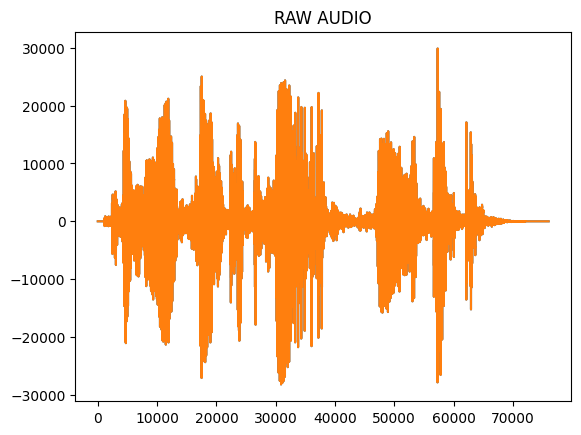

In [8]:
plt.plot(audio)
plt.title('RAW AUDIO')
plt.show()

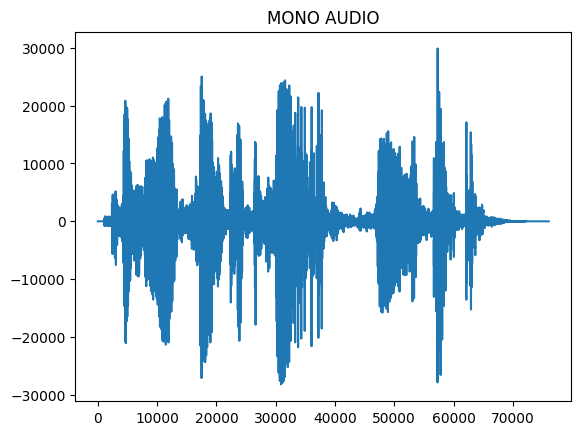

In [9]:
# Convert Stereo to Mono
if audio.ndim > 1: 
    audio = np.mean(audio, axis=1)
    
plt.plot(audio)
plt.title('MONO AUDIO')
plt.show()

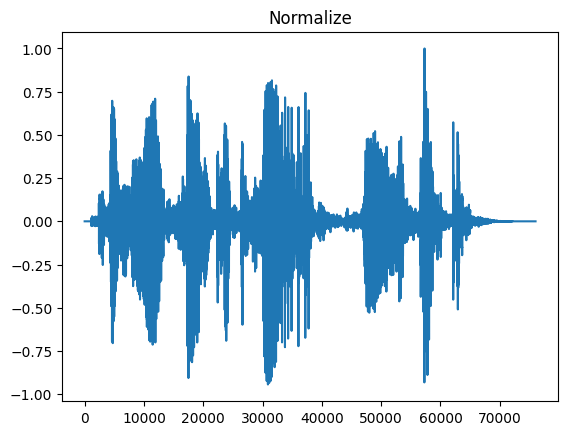

In [ ]:
# Normalization
norm_audio = audio / np.max(np.abs(audio))

# plt.plot(audio, label='Before Normalize')
plt.plot(norm_audio, label='After Normalize') # nilai jadi -1 sampe 1
plt.title('Normalize')
plt.show()

# Framing

In [ ]:
# Framing 
FFT_SIZE = 2048
HOP_SIZE = 15

pad_width = int(FFT_SIZE // 2) # // = bagi dalam bentuk floor
pad_audio = np.pad(norm_audio, pad_width, mode='reflect')
# padding reflect/mirroring: 
#    ABCDEFGHI
#  BAABCDEFGHIIH

HOP_LENGTH = int(np.round(sr * HOP_SIZE/1000))
frame_num = ((len(audio) - FFT_SIZE) // HOP_LENGTH) + 1

frames = np.zeros((frame_num, FFT_SIZE))

for i in range(frame_num): 
    start = i * HOP_LENGTH
    end = start + FFT_SIZE
    frames[i] = pad_audio[start:end]

[ 0.07999464  0.0936841   0.08541688 ... -0.08702346 -0.07996117
 -0.07865582]


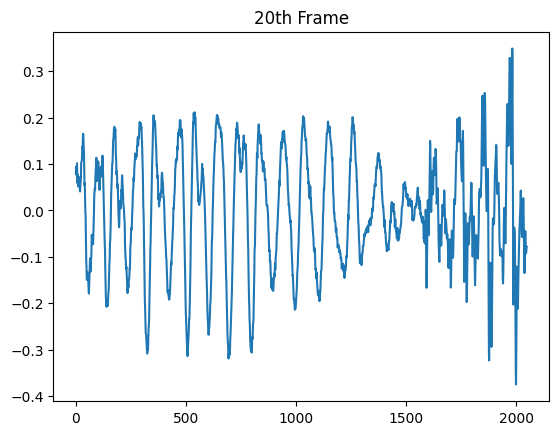

In [17]:
print(frames[20])

plt.plot(frames[20])
plt.title('20th Frame')
plt.show()

# Windowing

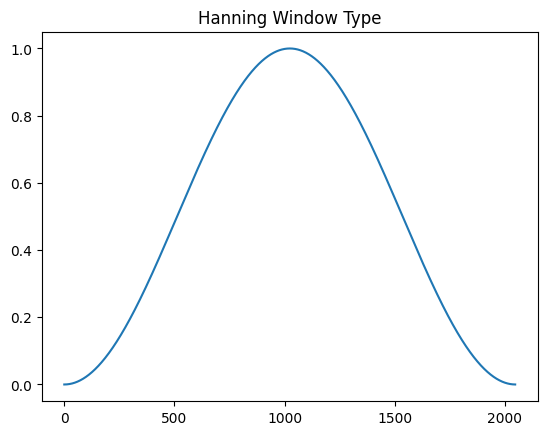

In [18]:
window_type = 'hann'
window = get_window(window_type, FFT_SIZE, fftbins=True)

plt.plot(window)
plt.title('Hanning Window Type')
plt.show()

[ 0.07999464  0.0936841   0.08541688 ... -0.08702346 -0.07996117
 -0.07865582]
[ 0.00000000e+00  2.20447619e-07  8.03974275e-07 ... -1.84295888e-06
 -7.52623253e-07 -1.85084639e-07]


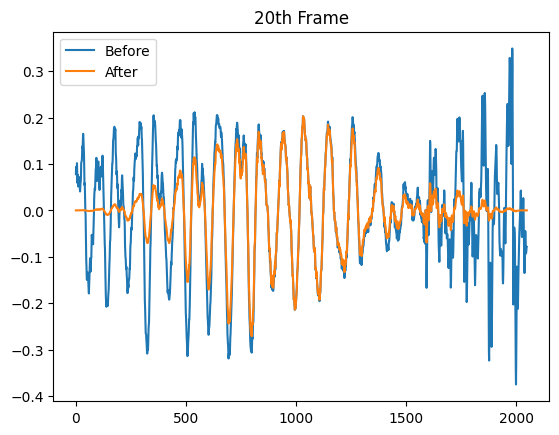

In [21]:
audio_win = frames * window

print(frames[20])
print(audio_win[20])
plt.plot(frames[20], label='Before')
plt.plot(audio_win[20], label='After')
plt.legend()
plt.title('20th Frame')
plt.show()

# FFT

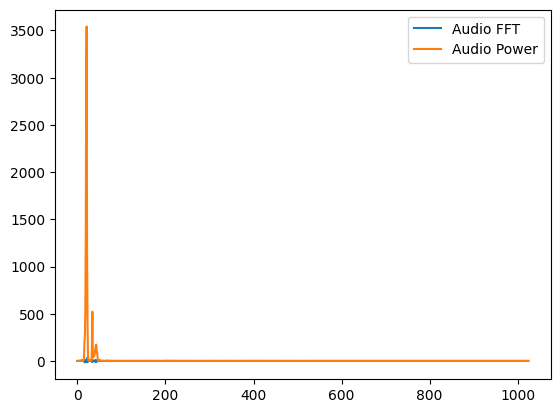

[9.7728157e-03 1.0491304e-02 2.5037518e-02 ... 7.8567535e-09 4.2289784e-08
 6.6639285e-12]


In [27]:
# FFT
audio_winT = np.transpose(audio_win)

audio_fft = np.empty(
    (1 + FFT_SIZE // 2, audio_winT.shape[1]), 
    dtype=np.complex64
)

for i in range(audio_fft.shape[1]): 
    fft_result = fft.fft(audio_winT[:, i])
    audio_fft[:, i] = fft_result[:audio_fft.shape[0]]
    
audio_fft = np.transpose(audio_fft)
    
audio_pow = np.square(np.abs(audio_fft))

# plt.plot(audio_win[20], label='Audio Win')
plt.plot(audio_fft[20], label='Audio FFT')
plt.plot(audio_pow[20], label='Audio Power')
plt.legend()
plt.show()
print(audio_pow[20])